In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import os

# Veriyi oku
os.chdir(r"C:\Users\emine\Desktop\rfm-xai-segmentation")
df = pd.read_csv("data/processed/rfm_clustered.csv")

# Özellikleri ve hedefi ayır
X = df[["Recency", "Frequency", "Monetary"]]
y = df["Cluster"]

# Eğitim/test bölünmesi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape


((3470, 3), (868, 3))

[[329   3   7]
 [ 11 144   0]
 [  2   0 372]]
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       339
           1       0.98      0.93      0.95       155
           2       0.98      0.99      0.99       374

    accuracy                           0.97       868
   macro avg       0.97      0.96      0.97       868
weighted avg       0.97      0.97      0.97       868



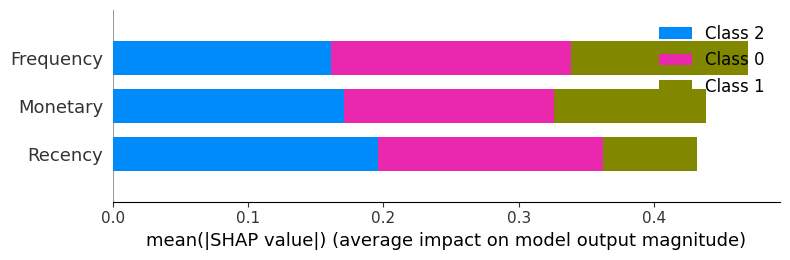

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import shap

# Modeli kur
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# Tahmin ve performans
y_pred = rf.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# SHAP değerleri
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Görselleştirme
shap.summary_plot(shap_values, X_test, plot_type="bar")
